In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler, MinMaxScaler

In [25]:
# Load the processed data
dpdk_df = pd.read_csv('../data/processed/dpdk_df_processed.csv')
oai_df = pd.read_csv('../data/processed/oai_df_processed.csv')

# Display the first few rows of each dataframe
print("DPDK Data:")
display(dpdk_df.head())

print("\nOAI Data:")
display(oai_df.head())

DPDK Data:


,timestamp,RAN_Tx_pks,RAN_Rx_pks,DN_Rx_pks,DN_Tx_pks,DN_pks_lost,RAN_pks_lost,DN_jitter,RAN_jitter,Test Case,...,Test Set,Objective Throughput (DL/UL),Packet Size,Packet Rate,total_throughput_mbps,total_packets_per_second,DN_pks_lost_interval,RAN_pks_lost_interval,DN_PLR_interval,RAN_PLR_interval
0,2025-01-03 16:25:39,0.0,0.0,1.0,1.0,0.0,0.0,1447.0,52.0,TC1,...,1,0.01,1250,1,0.019,1.0,0.0,0.0,0.0,0.0
1,2025-01-03 16:25:42,1.0,1.0,1.0,1.0,0.0,0.0,579.0,22.0,TC1,...,1,0.01,1250,1,0.020,2.0,0.0,0.0,0.0,0.0
2,2025-01-03 16:25:45,0.0,0.0,1.0,1.0,0.0,0.0,364.0,15.0,TC1,...,1,0.01,1250,1,0.020,1.0,0.0,0.0,0.0,0.0
3,2025-01-03 16:25:48,0.0,0.0,1.0,1.0,0.0,0.0,267.0,13.0,TC1,...,1,0.01,1250,1,0.019,1.0,0.0,0.0,0.0,0.0
4,2025-01-03 16:25:51,1.0,1.0,1.0,1.0,0.0,0.0,210.0,11.0,TC1,...,1,0.01,1250,1,0.020,2.0,0.0,0.0,0.0,0.0



OAI Data:


,timestamp,RAN_Tx_pks,RAN_Rx_pks,DN_Rx_pks,DN_Tx_pks,DN_pks_lost,RAN_pks_lost,DN_jitter,RAN_jitter,Test Case,...,Test Set,Objective Throughput (DL/UL),Packet Size,Packet Rate,total_packets_per_second,total_throughput_mbps,DN_pks_lost_interval,RAN_pks_lost_interval,DN_PLR_interval,RAN_PLR_interval
0,2025-01-13 13:09:06,0.0,0.0,1.0,1.0,0.0,0.0,355.0,596.0,TC1,...,1,0.01,1250,1,1.0,0.019,0.0,0.0,0.0,0.0
1,2025-01-13 13:09:09,1.0,1.0,1.0,1.0,0.0,0.0,152.0,279.0,TC1,...,1,0.01,1250,1,2.0,0.021,0.0,0.0,0.0,0.0
2,2025-01-13 13:09:12,0.0,0.0,1.0,1.0,0.0,0.0,103.0,167.0,TC1,...,1,0.01,1250,1,1.0,0.019,0.0,0.0,0.0,0.0
3,2025-01-13 13:09:15,0.0,0.0,1.0,1.0,0.0,0.0,82.0,129.0,TC1,...,1,0.01,1250,1,1.0,0.019,0.0,0.0,0.0,0.0
4,2025-01-13 13:09:18,0.0,0.0,0.0,0.0,0.0,0.0,69.0,103.0,TC1,...,1,0.01,1250,1,0.0,0.019,0.0,0.0,0.0,0.0


In [26]:
print("DPDK Columns:")
print(dpdk_df.columns)

print("\nOAI Columns:")
print(oai_df.columns)

DPDK Columns:
Index(['timestamp', 'RAN_Tx_pks', 'RAN_Rx_pks', 'DN_Rx_pks', 'DN_Tx_pks',
       'DN_pks_lost', 'RAN_pks_lost', 'DN_jitter', 'RAN_jitter', 'Test Case',
       'cpu_usage_percentage', 'DN_Tx_Mbits/s', 'DN_Rx_Mbits/s',
       'RAN_Tx_Mbits/s', 'RAN_Rx_Mbits/s', 'uplink_delay_ms',
       'downlink_delay_ms', 'power_consumption_watts', 'Test Set',
       'Objective Throughput (DL/UL)', 'Packet Size', 'Packet Rate',
       'total_throughput_mbps', 'total_packets_per_second',
       'DN_pks_lost_interval', 'RAN_pks_lost_interval', 'DN_PLR_interval',
       'RAN_PLR_interval'],
      dtype='object')

OAI Columns:
Index(['timestamp', 'RAN_Tx_pks', 'RAN_Rx_pks', 'DN_Rx_pks', 'DN_Tx_pks',
       'DN_pks_lost', 'RAN_pks_lost', 'DN_jitter', 'RAN_jitter', 'Test Case',
       'cpu_usage_percentage', 'DN_Tx_Mbits/s', 'DN_Rx_Mbits/s',
       'RAN_Tx_Mbits/s', 'RAN_Rx_Mbits/s', 'uplink_delay_ms',
       'downlink_delay_ms', 'power_consumption_watts', 'Test Set',
       'Objective Throughp

QoS : Data-Driven

In [14]:
def bounded_score_low_is_bad(x, cap):
    x = np.clip(x, 0, cap)
    return 1.0 - (x / cap)

def throughput_fulfillment(delivered, objective, eps=1e-9):
    return np.clip(delivered / (objective + eps), 0.0, 1.0)

def compute_component_scores(df, *, 
                             delivered_col="Avg DL Throughput (Mbps)",
                             objective_col="Avg Objective Throughput (Mbps)",
                             delay_col="Avg DL Delay (ms)",
                             jitter_col="Avg DL Jitter (us)",
                             loss_frac_col="Total Packet Loss (%)",  # e.g., lost/tx
                             D_max=40.0, J_max=10.0, L_max=5):
    S_th   = throughput_fulfillment(df[delivered_col].values, df[objective_col].values)
    S_lat  = bounded_score_low_is_bad(df[delay_col].values,  D_max)
    S_jit  = bounded_score_low_is_bad(df[jitter_col].values, J_max)
    S_loss = bounded_score_low_is_bad(df[loss_frac_col].values, L_max)
    return np.vstack([S_th, S_lat, S_jit, S_loss]).T  # shape: (n,4)

def weighted_qos(S, w=(0.40, 0.20, 0.20, 0.20)):
    W = np.asarray(w)/np.sum(w)
    return (S * W).sum(axis=1)

def data_driven_qos(S, random_state=0):
    scaler_z = StandardScaler()
    Z = scaler_z.fit_transform(S)
    pca = PCA(n_components=1, random_state=random_state)
    pc1 = pca.fit_transform(Z).ravel()
    # Flip so higher is better: correlate with S_th (col 0)
    if np.corrcoef(pc1, S[:,0])[0,1] < 0:
        pc1 = -pc1
    scaler_s = MinMaxScaler()
    q_dd = scaler_s.fit_transform(pc1.reshape(-1,1)).ravel()
    return q_dd, {"scaler_z": scaler_z, "pca": pca, "scaler_s": scaler_s}


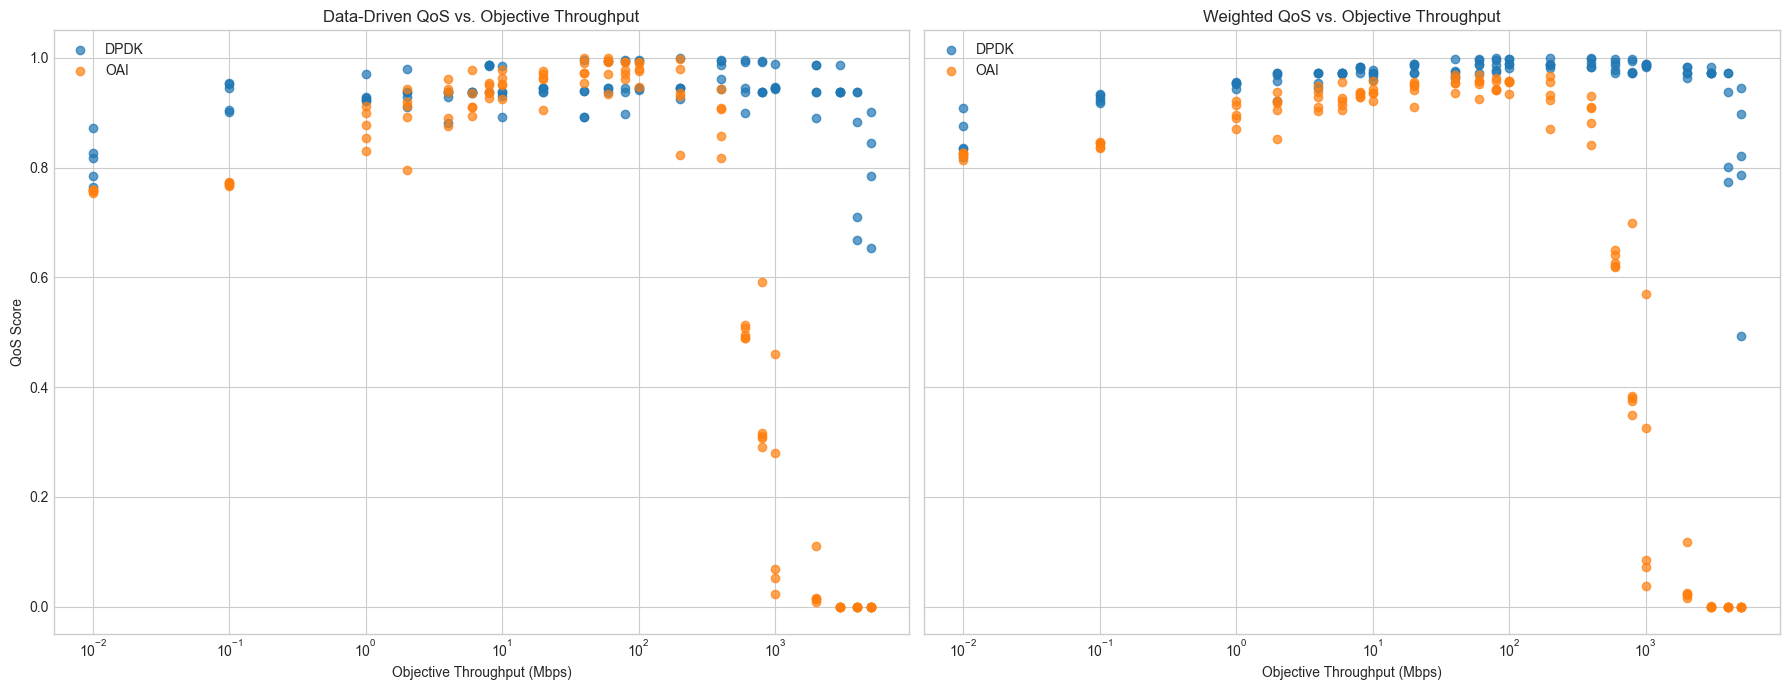

In [24]:
# Create a figure with two subplots
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(18, 7), sharey=True)

objective_throughput_col = 'Avg Objective Throughput (Mbps)'

# Plot for Data-Driven QoS
ax1.scatter(dpdk_df[objective_throughput_col], dpdk_df['QoS_dd'], label='DPDK', alpha=0.7)
ax1.scatter(oai_df[objective_throughput_col], oai_df['QoS_dd'], label='OAI', alpha=0.7)
ax1.set_title('Data-Driven QoS vs. Objective Throughput')
ax1.set_xlabel('Objective Throughput (Mbps)')
ax1.set_ylabel('QoS Score')
ax1.legend()
ax1.grid(True)
ax1.set_xscale('log')
# Plot for Weighted QoS
ax2.scatter(dpdk_df[objective_throughput_col], dpdk_df['QoS_w'], label='DPDK', alpha=0.7)
ax2.scatter(oai_df[objective_throughput_col], oai_df['QoS_w'], label='OAI', alpha=0.7)
ax2.set_title('Weighted QoS vs. Objective Throughput')
ax2.set_xlabel('Objective Throughput (Mbps)')
ax2.legend()
ax2.grid(True)
ax2.set_xscale('log')
# Show the plots
plt.tight_layout()
plt.show()

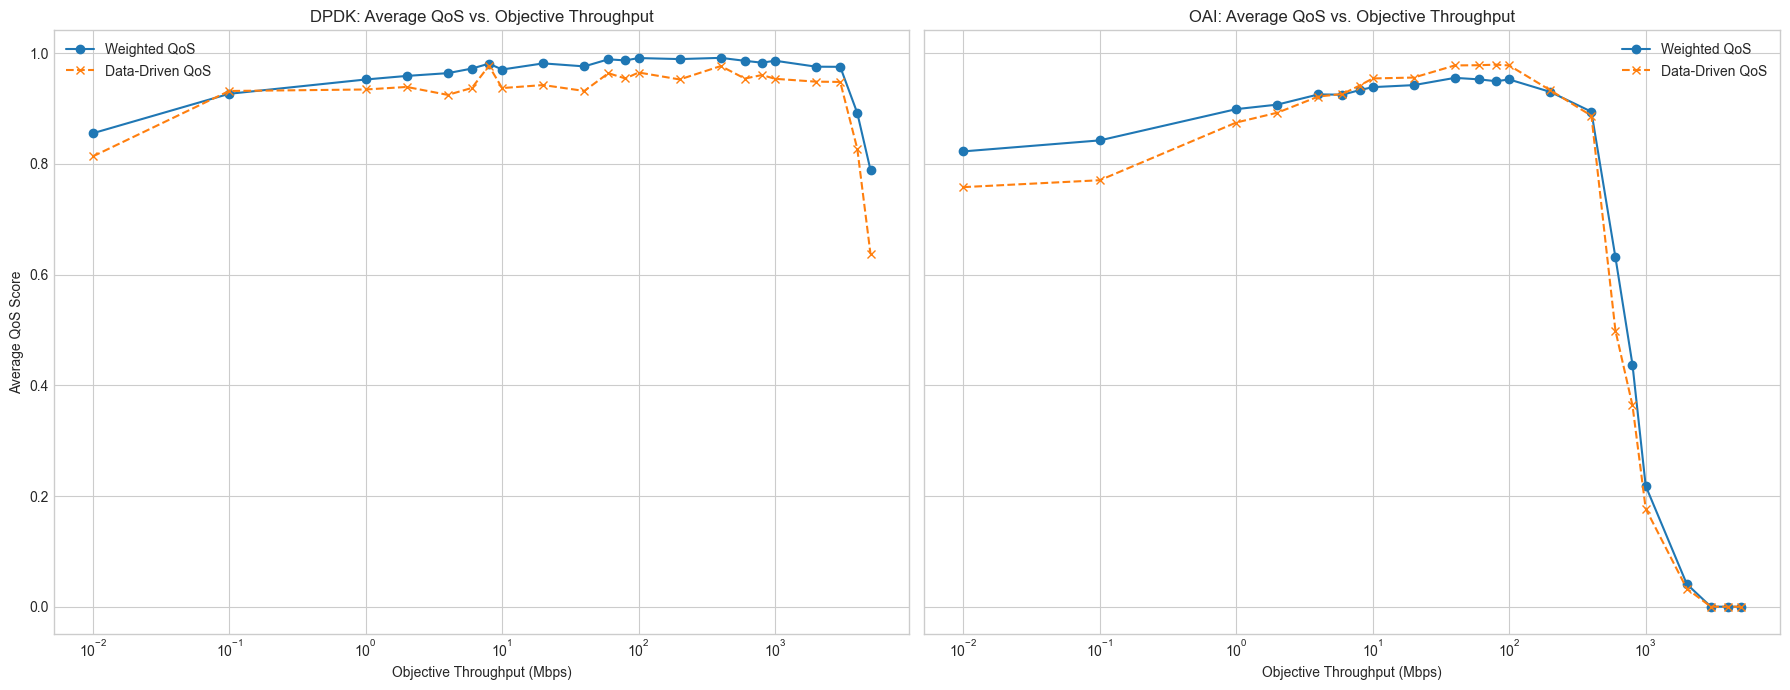

In [16]:
# Group by objective throughput and calculate the mean QoS for both methods
dpdk_avg_qos = dpdk_df.groupby(objective_throughput_col)[['QoS_w', 'QoS_dd']].mean()
oai_avg_qos = oai_df.groupby(objective_throughput_col)[['QoS_w', 'QoS_dd']].mean()

# Create a figure with two subplots
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(18, 7), sharey=True)

# Plot for DPDK
ax1.plot(dpdk_avg_qos.index, dpdk_avg_qos['QoS_w'], label='Weighted QoS', marker='o', linestyle='-')
ax1.plot(dpdk_avg_qos.index, dpdk_avg_qos['QoS_dd'], label='Data-Driven QoS', marker='x', linestyle='--')
ax1.set_title('DPDK: Average QoS vs. Objective Throughput')
ax1.set_xlabel('Objective Throughput (Mbps)')
ax1.set_ylabel('Average QoS Score')
ax1.legend()
ax1.grid(True)
ax1.set_xscale('log')

# Plot for OAI
ax2.plot(oai_avg_qos.index, oai_avg_qos['QoS_w'], label='Weighted QoS', marker='o', linestyle='-')
ax2.plot(oai_avg_qos.index, oai_avg_qos['QoS_dd'], label='Data-Driven QoS', marker='x', linestyle='--')
ax2.set_title('OAI: Average QoS vs. Objective Throughput')
ax2.set_xlabel('Objective Throughput (Mbps)')
ax2.legend()
ax2.grid(True)
ax2.set_xscale('log')

# Show the plots
plt.tight_layout()
plt.show()

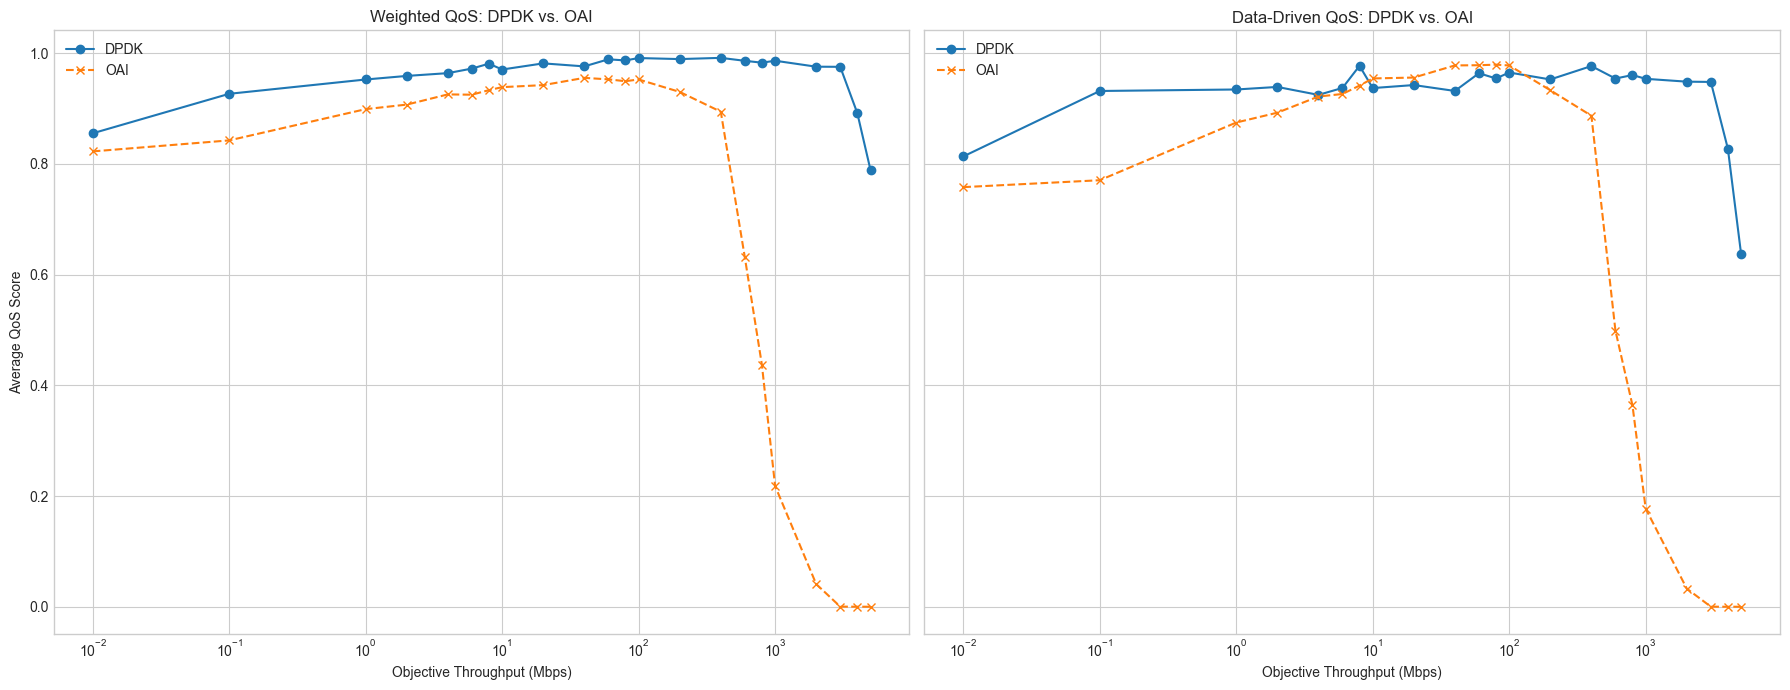

In [22]:
# Create a figure with two subplots, this time separating by QoS method
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(18, 7), sharey=True)

# Plot for Weighted QoS
ax1.plot(dpdk_avg_qos.index, dpdk_avg_qos['QoS_w'], label='DPDK', marker='o', linestyle='-')
ax1.plot(oai_avg_qos.index, oai_avg_qos['QoS_w'], label='OAI', marker='x', linestyle='--')
ax1.set_title('Weighted QoS: DPDK vs. OAI')
ax1.set_xlabel('Objective Throughput (Mbps)')
ax1.set_ylabel('Average QoS Score')
ax1.legend()
ax1.grid(True)
ax1.set_xscale('log')
# ax1.set_yscale('log')
# Plot for Data-Driven QoS
ax2.plot(dpdk_avg_qos.index, dpdk_avg_qos['QoS_dd'], label='DPDK', marker='o', linestyle='-')
ax2.plot(oai_avg_qos.index, oai_avg_qos['QoS_dd'], label='OAI', marker='x', linestyle='--')
ax2.set_title('Data-Driven QoS: DPDK vs. OAI')
ax2.set_xlabel('Objective Throughput (Mbps)')
ax2.legend()
ax2.grid(True)
ax2.set_xscale('log')
# ax2.set_yscale('log')
# Show the plots
plt.tight_layout()
plt.show()